# ch04 波士顿房价预测（线性回归）

In [1]:
# (1) 导入必要的库
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 说明：sklearn 1.2 起 load_boston 已被移除，此处做兼容处理：
# 新版本改用 fetch_openml 获取同名 Boston 数据集，接口与 load_boston 一致。
try:
    from sklearn.datasets import load_boston
    boston = load_boston()
except ImportError:
    from sklearn.datasets import fetch_openml
    boston = fetch_openml(name='boston', version=1, as_frame=False, parser='auto')

print('sklearn 版本:', __import__('sklearn').__version__)

sklearn 版本: 1.7.2


## (2) 加载 Boston 房价数据集
`boston.data` 是特征矩阵，`boston.target` 是目标值（房价中位数），`boston.feature_names` 是特征名称。

In [2]:
# (2) 查看数据集基本信息
print('特征矩阵 shape:', boston.data.shape)
print('目标值 shape:', boston.target.shape)
print('特征名称:', list(boston.feature_names))

特征矩阵 shape: (506, 13)
目标值 shape: (506,)
特征名称: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


In [3]:
# (3) 转换为 pandas 的 DataFrame，特征列名为 boston.feature_names，目标列命名为 MEDV
df = pd.DataFrame(boston.data, columns=boston.feature_names)
df['MEDV'] = boston.target
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.09,1,296.0,15.3,396.9,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.9,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.9,5.33,36.2


In [4]:
# (4) 查看并打印 DataFrame 的前 5 行和数据形状
print('前 5 行：')
print(df.head())
print('\n数据形状:', df.shape)

前 5 行：
      CRIM    ZN INDUS CHAS    NOX     RM   AGE     DIS RAD    TAX PTRATIO  \
0  0.00632  18.0  2.31    0  0.538  6.575  65.2    4.09   1  296.0    15.3   
1  0.02731   0.0  7.07    0  0.469  6.421  78.9  4.9671   2  242.0    17.8   
2  0.02729   0.0  7.07    0  0.469  7.185  61.1  4.9671   2  242.0    17.8   
3  0.03237   0.0  2.18    0  0.458  6.998  45.8  6.0622   3  222.0    18.7   
4  0.06905   0.0  2.18    0  0.458  7.147  54.2  6.0622   3  222.0    18.7   

        B LSTAT  MEDV  
0   396.9  4.98  24.0  
1   396.9  9.14  21.6  
2  392.83  4.03  34.7  
3  394.63  2.94  33.4  
4   396.9  5.33  36.2  

数据形状: (506, 14)


In [5]:
# (5) 分离特征 X 和目标 y
X = df[boston.feature_names]
y = df['MEDV']
print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (506, 13)
y shape: (506,)


In [6]:
# (6) 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('训练集 shape:', X_train.shape, y_train.shape)
print('测试集 shape:', X_test.shape, y_test.shape)

训练集 shape: (404, 13) (404,)
测试集 shape: (102, 13) (102,)


In [7]:
# (7) 创建线性回归模型，训练并在测试集上计算 R² 分数
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = model.score(X_test, y_test)
print('测试集 R² 分数: {:.4f}'.format(r2))

测试集 R² 分数: 0.6688


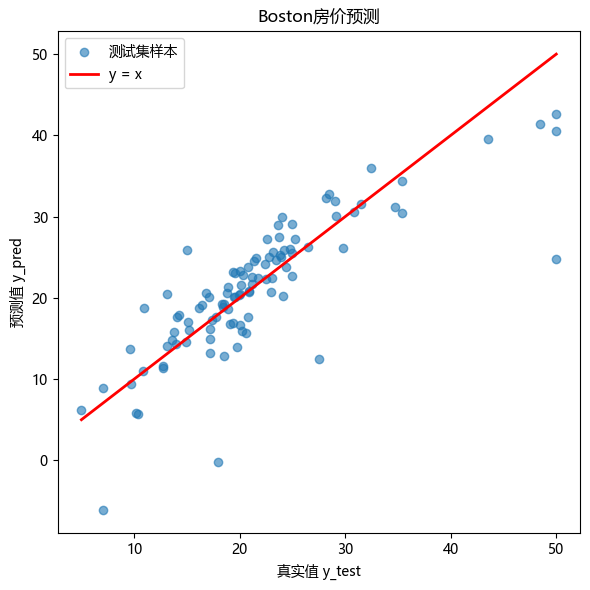

In [8]:
# (8) 真实值 vs 预测值散点图，并添加红色 y=x 参考线
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']   # 正常显示中文
plt.rcParams['axes.unicode_minus'] = False                        # 正常显示负号

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6, label='测试集样本')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         color='red', linewidth=2, label='y = x')
plt.title('Boston房价预测')
plt.xlabel('真实值 y_test')
plt.ylabel('预测值 y_pred')
plt.legend()
plt.tight_layout()
plt.show()